In [2]:
import pandas as pd

reviews = pd.read_csv("IMDB Dataset.csv")

print("Dataset shape:", reviews.shape)
print("\nColumn names:", reviews.columns.tolist())
display(reviews.head())


Dataset shape: (50000, 2)

Column names: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
reviews["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [6]:
# Check the dataset size and structure
print("Dataset shape:", reviews.shape)
print("\nColumn names:")
print(reviews.columns.tolist())

# Check missing values
print("\nMissing values:")
print(reviews.isnull().sum())

# Check duplicate reviews
print("\nDuplicate rows:", reviews.duplicated().sum())

# Check positive and negative labels
print("\nSentiment distribution:")
print(reviews["sentiment"].value_counts())

# Check a few reviews
display(reviews.head())


Dataset shape: (50000, 2)

Column names:
['review', 'sentiment']

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [8]:
import re
import html

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<.*?>", " ", text)  # Remove HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text)    # Normalize spaces
    return text.strip()

reviews["clean_review"] = reviews["review"].apply(clean_text)

display(reviews[["review", "clean_review", "sentiment"]].head())


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...","Petter Mattei's ""Love in the Time of Money"" is...",positive


In [10]:
reviews["sentiment_label"] = reviews["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(reviews["sentiment_label"].value_counts())
print("Missing encoded labels:", reviews["sentiment_label"].isnull().sum())


sentiment_label
1    25000
0    25000
Name: count, dtype: int64
Missing encoded labels: 0


In [12]:
from sklearn.model_selection import train_test_split

X = reviews["clean_review"]
y = reviews["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))


Training reviews: 40000
Testing reviews: 10000


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)


Training matrix: (40000, 30000)
Testing matrix: (10000, 30000)


In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

logistic_predictions = logistic_model.predict(X_test_tfidf)

print("Logistic Regression training complete.")


Logistic Regression training complete.


In [20]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes training complete.")


Multinomial Naive Bayes training complete.


In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 40)
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall:", round(recall_score(y_true, y_pred), 4))
    print("F1-score:", round(f1_score(y_true, y_pred), 4))
    print("\nClassification report:")
    print(classification_report(
        y_true, y_pred,
        target_names=["Negative", "Positive"]
    ))

evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)

evaluate_model(
    "Multinomial Naive Bayes",
    y_test,
    nb_predictions
)



Logistic Regression
----------------------------------------
Accuracy: 0.9086
Precision: 0.9034
Recall: 0.915
F1-score: 0.9092

Classification report:
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.91      5000
    Positive       0.90      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000


Multinomial Naive Bayes
----------------------------------------
Accuracy: 0.8796
Precision: 0.8742
Recall: 0.8868
F1-score: 0.8805

Classification report:
              precision    recall  f1-score   support

    Negative       0.89      0.87      0.88      5000
    Positive       0.87      0.89      0.88      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



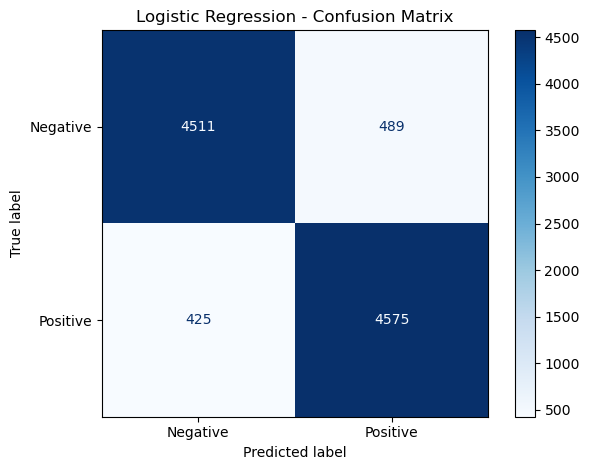

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9086,0.9034,0.9150,0.9092
1,Multinomial Naive Bayes,0.8796,0.8742,0.8868,0.8805


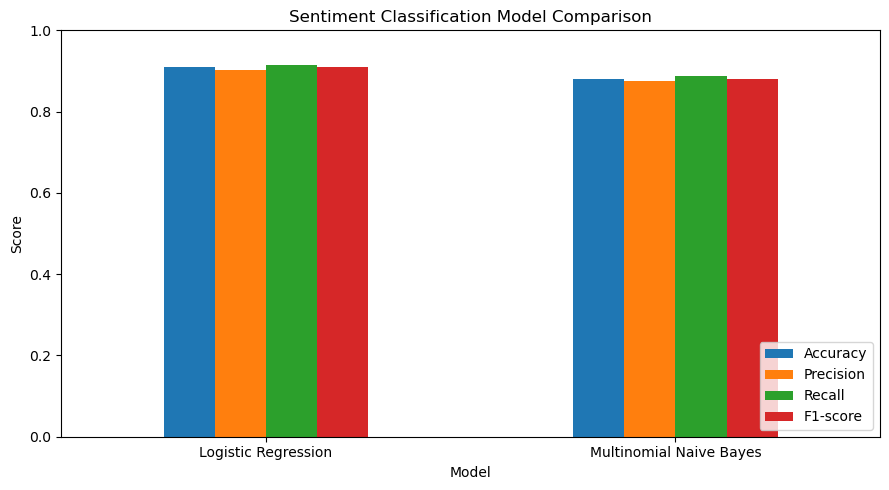

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, logistic_predictions),
        "Precision": precision_score(y_test, logistic_predictions),
        "Recall": recall_score(y_test, logistic_predictions),
        "F1-score": f1_score(y_test, logistic_predictions)
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": accuracy_score(y_test, nb_predictions),
        "Precision": precision_score(y_test, nb_predictions),
        "Recall": recall_score(y_test, nb_predictions),
        "F1-score": f1_score(y_test, nb_predictions)
    }
])

display(results.round(4))

results.set_index("Model").plot(
    kind="bar",
    ylim=(0, 1),
    figsize=(9, 5)
)

plt.title("Sentiment Classification Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [28]:
import numpy as np

feature_names = tfidf.get_feature_names_out()
coefficients = logistic_model.coef_[0]

top_positive = np.argsort(coefficients)[-15:][::-1]
top_negative = np.argsort(coefficients)[:15]

print("Words most associated with positive sentiment:")
print(feature_names[top_positive])

print("\nWords most associated with negative sentiment:")
print(feature_names[top_negative])


Words most associated with positive sentiment:
['great' 'excellent' 'perfect' 'wonderful' 'amazing' 'the best' 'fun'
 'brilliant' 'loved' 'hilarious' 'enjoyed' 'best' 'today' 'superb'
 'enjoyable']

Words most associated with negative sentiment:
['bad' 'worst' 'awful' 'boring' 'the worst' 'waste' 'poor' 'terrible'
 'nothing' 'dull' 'stupid' 'worse' 'horrible' 'poorly' 'ridiculous']


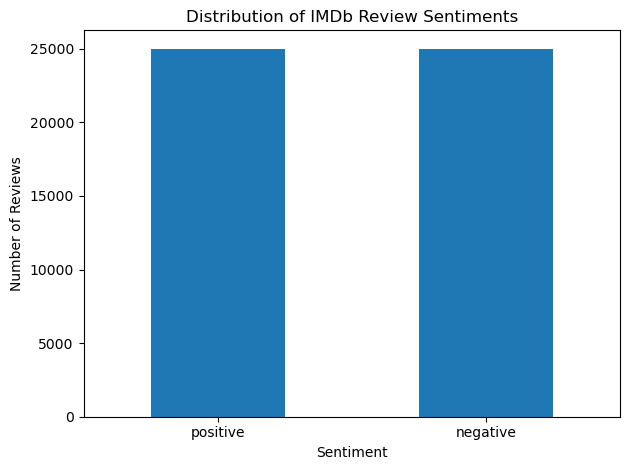

In [30]:
import matplotlib.pyplot as plt

sentiment_counts = reviews["sentiment"].value_counts()

sentiment_counts.plot(kind="bar", rot=0)

plt.title("Distribution of IMDb Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [32]:
sample_review = [
    "The movie was beautifully acted and had a wonderful story."
]

sample_clean = [clean_text(sample_review[0])]
sample_features = tfidf.transform(sample_clean)

prediction = logistic_model.predict(sample_features)[0]
probabilities = logistic_model.predict_proba(sample_features)[0]

label = "Positive" if prediction == 1 else "Negative"

print("Review:", sample_review[0])
print("Predicted sentiment:", label)
print("Negative probability:", round(probabilities[0], 4))
print("Positive probability:", round(probabilities[1], 4))


Review: The movie was beautifully acted and had a wonderful story.
Predicted sentiment: Positive
Negative probability: 0.1061
Positive probability: 0.8939


In [34]:
# Save model comparison metrics
results.to_csv("imdb_sentiment_model_comparison.csv", index=False)

# Save a small sample of cleaned reviews and their labels
reviews[["clean_review", "sentiment"]].head(1000).to_csv(
    "imdb_cleaned_reviews_sample.csv",
    index=False
)

print("Saved model comparison and cleaned review sample.")


Saved model comparison and cleaned review sample.


In [36]:

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9086,0.9034,0.9150,0.9092
1,Multinomial Naive Bayes,0.8796,0.8742,0.8868,0.8805


In [40]:
plt.savefig("sentiment_model_comparison.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [42]:
plt.savefig("sentiment_confusion_matrix.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>